# Handwritten Digit Recognition: CNN vs Small Vision Transformer (ViT)

**Dataset:** `sklearn.datasets.load_digits()`  
**Task:** Classify handwritten digits (0–9) from 8×8 grayscale images.  
**Models:** A small CNN and an attention-based ViT implemented in PyTorch.

This notebook follows the uploaded Module 04 student rubric:
- Use the sklearn 8×8 digits dataset (pixel values 0–16).
- Divide pixels by 16 so model inputs are in [0, 1].
- Use one shared, stratified train/validation/test split for both models.
- CNN input: `[batch, 1, 8, 8]`, with ten output logits.
- ViT input: sixteen non-overlapping 2×2 patches, each containing four values (`[batch, 16, 4]`), with learned patch projection, positional embeddings and Transformer attention.
- Compare test accuracy, macro F1 and confusion matrices; include a majority-class baseline.
- Save both model checkpoints and reusable image-preparation settings/functions.

> **Important:** Keep the test set untouched during training and model selection. The notebook uses validation data to select the best epoch. Real uploaded photos may still be harder than sklearn's small, centered digit images.

## 1. Install and import dependencies

Run the install cell if these packages are not already available in your environment.

In [17]:
# If needed, uncomment and run:
# %pip install torch scikit-learn pillow numpy matplotlib

In [18]:
import copy
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline 
from PIL import Image, ImageOps

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

PyTorch: 2.15.0+cpu
Device: cpu


## 2. Load and explore the sklearn digits dataset

Each sample is an 8×8 grayscale image. Original pixel values are integers from 0 to 16, and labels are digits 0 through 9.

In [19]:
digits = load_digits()
X_raw = digits.images.astype(np.float32)  # [n_samples, 8, 8], values 0..16
y = digits.target.astype(np.int64)

print("Images:", X_raw.shape)
print("Labels:", y.shape)
print("Pixel min/max:", X_raw.min(), X_raw.max())
print("Classes:", np.unique(y))

Images: (1797, 8, 8)
Labels: (1797,)
Pixel min/max: 0.0 16.0
Classes: [0 1 2 3 4 5 6 7 8 9]


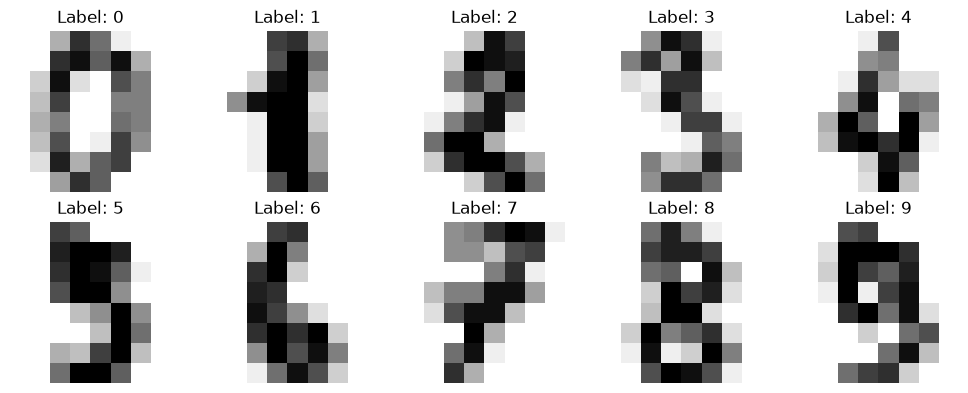

In [20]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for digit, ax in enumerate(axes.ravel()):
    idx = np.where(y == digit)[0][0]
    ax.imshow(X_raw[idx], cmap="gray_r", vmin=0, vmax=16)
    ax.set_title(f"Label: {y[idx]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Scale pixels and create one shared stratified split

The rubric specifies dividing sklearn pixel values by 16. We create the split once and reuse its indices for both models.

Split proportions: 70% train, 15% validation, 15% test. Stratification preserves class proportions. The test set is held aside until final evaluation.

In [21]:
# Match the training scale specified in the project guide: 0..16 -> 0..1
X = X_raw / 16.0

all_indices = np.arange(len(y))
train_idx, temp_idx = train_test_split(
    all_indices,
    test_size=0.30,
    random_state=SEED,
    stratify=y,
)
val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=SEED,
    stratify=y[temp_idx],
)

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

print(f"Train: {len(train_idx)} ({len(train_idx)/len(y):.1%})")
print(f"Validation: {len(val_idx)} ({len(val_idx)/len(y):.1%})")
print(f"Test: {len(test_idx)} ({len(test_idx)/len(y):.1%})")
print("Scaled pixel range:", X.min(), X.max())

Train: 1257 (69.9%)
Validation: 270 (15.0%)
Test: 270 (15.0%)
Scaled pixel range: 0.0 1.0


In [22]:
# Verify each split contains all ten classes.
for name, labels in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    print(name, np.unique(labels, return_counts=True))

train (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([124, 127, 124, 128, 127, 127, 127, 125, 122, 126]))
validation (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([27, 27, 27, 27, 27, 28, 27, 27, 26, 27]))
test (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([27, 28, 26, 28, 27, 27, 27, 27, 26, 27]))


## 4. Create PyTorch datasets and data loaders

The CNN receives images shaped `[N, 1, 8, 8]`. The ViT will receive the same image tensors and create patches inside its forward pass.

In [23]:
def make_loader(images, labels, batch_size=64, shuffle=False):
    image_tensor = torch.tensor(images, dtype=torch.float32).unsqueeze(1)
    label_tensor = torch.tensor(labels, dtype=torch.long)
    dataset = TensorDataset(image_tensor, label_tensor)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)

BATCH_SIZE = 64
train_loader = make_loader(X_train, y_train, BATCH_SIZE, shuffle=True)
val_loader = make_loader(X_val, y_val, BATCH_SIZE)
test_loader = make_loader(X_test, y_test, BATCH_SIZE)

xb, yb = next(iter(train_loader))
print("CNN image batch:", xb.shape)  # [batch, 1, 8, 8]
print("Label batch:", yb.shape)

CNN image batch: torch.Size([64, 1, 8, 8])
Label batch: torch.Size([64])


## 5. Model A - Convolutional Neural Network (CNN)

This compact CNN uses two convolutional layers to learn local visual features. The classifier returns **ten logits** (one score per digit). `CrossEntropyLoss` expects raw logits, so do not add softmax in the model.

In [24]:
class SmallCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),  # 8x8 -> 4x4
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(p=0.30),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

cnn_model = SmallCNN().to(DEVICE)
print(cnn_model)
with torch.no_grad():
    sample_logits = cnn_model(xb[:4].to(DEVICE))
print("CNN output shape:", sample_logits.shape)  # [4, 10]

SmallCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1024, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
CNN output shape: torch.Size([4, 10])


## 6. Model B — Small attention-based Vision Transformer (ViT)

The ViT follows the required patch design:
1. Split each 8×8 image into sixteen non-overlapping 2×2 patches.
2. Flatten each patch into four values: `[batch, 16, 4]`.
3. Project each four-value patch into a 64-dimensional embedding.
4. Add learned positional embeddings and a learnable class token.
5. Process tokens with Transformer encoder attention.
6. Classify the class-token representation into ten digits.

In [27]:
class SmallViT(nn.Module):
    def __init__(
        self,
        image_size=8,
        patch_size=2,
        in_channels=1,
        embed_dim=64,
        num_heads=4,
        num_layers=2,
        mlp_dim=128,
        num_classes=10,
        dropout=0.10,
    ):
        super().__init__()
        assert image_size % patch_size == 0
        self.image_size = image_size
        self.patch_size = patch_size
        self.num_patches = (image_size // patch_size) ** 2
        patch_dim = in_channels * patch_size * patch_size

        self.patch_projection = nn.Linear(patch_dim, embed_dim)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.position_embedding = nn.Parameter(
            torch.zeros(1, self.num_patches + 1, embed_dim)
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=mlp_dim,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True,
        )
        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers,
            enable_nested_tensor=False,

        )
        self.norm = nn.LayerNorm(embed_dim)
        self.head = nn.Linear(embed_dim, num_classes)

        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.trunc_normal_(self.position_embedding, std=0.02)

    def make_patches(self, x):
        # x: [B, 1, 8, 8]
        # Result: [B, 16, 4] for 2x2 patches
        b = x.shape[0]
        p = self.patch_size
        patches = x.unfold(2, p, p).unfold(3, p, p)
        patches = patches.permute(0, 2, 3, 1, 4, 5).contiguous()
        return patches.view(b, self.num_patches, -1)

    def forward(self, x):
        patches = self.make_patches(x)
        tokens = self.patch_projection(patches)
        cls_tokens = self.cls_token.expand(x.shape[0], -1, -1)
        tokens = torch.cat([cls_tokens, tokens], dim=1)
        tokens = tokens + self.position_embedding
        tokens = self.transformer(tokens)
        cls_representation = self.norm(tokens[:, 0])
        return self.head(cls_representation)

vit_model = SmallViT().to(DEVICE)
print(vit_model)
with torch.no_grad():
    example_patches = vit_model.make_patches(xb[:4].to(DEVICE))
    vit_logits = vit_model(xb[:4].to(DEVICE))
print("Patch tensor shape:", example_patches.shape)  # [4, 16, 4]
print("ViT output shape:", vit_logits.shape)         # [4, 10]

SmallViT(
  (patch_projection): Linear(in_features=4, out_features=64, bias=True)
  (transformer): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (linear1): Linear(in_features=64, out_features=128, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=128, out_features=64, bias=True)
        (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
  (head): Linear(in_features=64, out_features=10, bias=True)
)
Patch tensor shape: torch.Size([4, 16, 4])
ViT output sh

## 7. Shared training and validation utilities

Both models use the same training/validation data, loss function, optimizer type and epoch-selection rule. We save the weights from the epoch with the best validation accuracy. The test set is not used here.

In [28]:
def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss = 0.0
    all_true, all_pred = [], []

    for images, labels in loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * images.size(0)
        predictions = logits.argmax(dim=1)
        all_true.extend(labels.detach().cpu().numpy())
        all_pred.extend(predictions.detach().cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    accuracy = accuracy_score(all_true, all_pred)
    return avg_loss, accuracy

def train_model(model, train_loader, val_loader, epochs=30, learning_rate=1e-3):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    history = {
        "train_loss": [], "train_accuracy": [],
        "val_loss": [], "val_accuracy": [],
    }
    best_val_accuracy = -1.0
    best_state = copy.deepcopy(model.state_dict())

    for epoch in range(1, epochs + 1):
        train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc = run_epoch(model, val_loader, criterion)

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_acc)

        if val_acc > best_val_accuracy:
            best_val_accuracy = val_acc
            best_state = copy.deepcopy(model.state_dict())

        print(
            f"Epoch {epoch:02d}/{epochs} | "
            f"train loss {train_loss:.4f}, acc {train_acc:.4f} | "
            f"val loss {val_loss:.4f}, acc {val_acc:.4f}"
        )

    model.load_state_dict(best_state)
    return model, history

## 8. Train the CNN

You can lower `EPOCHS` for a quick smoke test, then increase it for the final run.

In [29]:
EPOCHS = 30

cnn_model, cnn_history = train_model(
    cnn_model,
    train_loader,
    val_loader,
    epochs=EPOCHS,
    learning_rate=1e-3,
)

Epoch 01/30 | train loss 2.1668, acc 0.3238 | val loss 1.8220, acc 0.7296
Epoch 02/30 | train loss 1.2684, acc 0.7208 | val loss 0.6393, acc 0.8185
Epoch 03/30 | train loss 0.4749, acc 0.8656 | val loss 0.3324, acc 0.8852
Epoch 04/30 | train loss 0.2940, acc 0.9085 | val loss 0.2116, acc 0.9444
Epoch 05/30 | train loss 0.2164, acc 0.9379 | val loss 0.1734, acc 0.9556
Epoch 06/30 | train loss 0.1510, acc 0.9547 | val loss 0.1441, acc 0.9630
Epoch 07/30 | train loss 0.1268, acc 0.9642 | val loss 0.1487, acc 0.9630
Epoch 08/30 | train loss 0.1129, acc 0.9650 | val loss 0.1113, acc 0.9667
Epoch 09/30 | train loss 0.0831, acc 0.9793 | val loss 0.1176, acc 0.9593
Epoch 10/30 | train loss 0.0747, acc 0.9785 | val loss 0.1002, acc 0.9704
Epoch 11/30 | train loss 0.0675, acc 0.9817 | val loss 0.0941, acc 0.9704
Epoch 12/30 | train loss 0.0541, acc 0.9857 | val loss 0.0966, acc 0.9667
Epoch 13/30 | train loss 0.0412, acc 0.9912 | val loss 0.1002, acc 0.9704
Epoch 14/30 | train loss 0.0614, acc 0

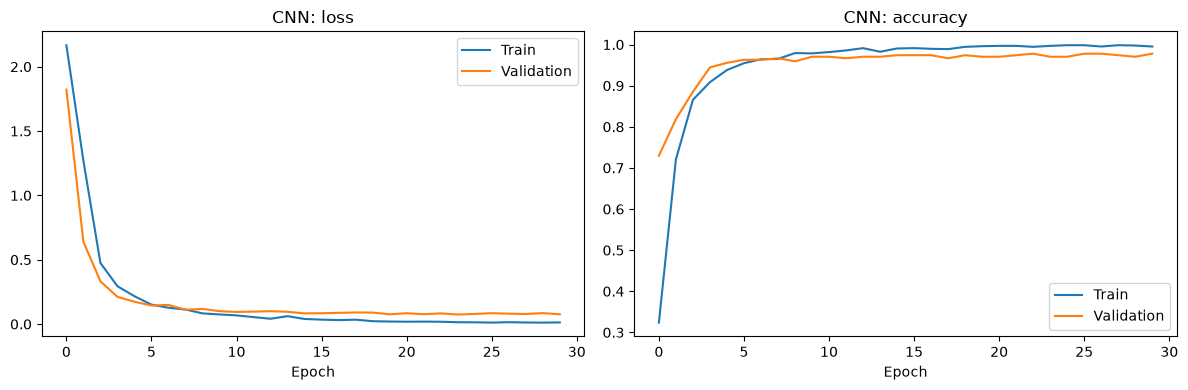

In [30]:
def plot_history(history, model_name):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history["train_loss"], label="Train")
    axes[0].plot(history["val_loss"], label="Validation")
    axes[0].set_title(f"{model_name}: loss")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()

    axes[1].plot(history["train_accuracy"], label="Train")
    axes[1].plot(history["val_accuracy"], label="Validation")
    axes[1].set_title(f"{model_name}: accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

plot_history(cnn_history, "CNN")

## 9. Train the Vision Transformer

Epoch 01/30 | train loss 2.3413, acc 0.0947 | val loss 2.3011, acc 0.1667
Epoch 02/30 | train loss 2.2972, acc 0.1392 | val loss 2.2592, acc 0.1593
Epoch 03/30 | train loss 2.2182, acc 0.1877 | val loss 2.0985, acc 0.2111
Epoch 04/30 | train loss 1.9013, acc 0.3174 | val loss 1.6650, acc 0.4556
Epoch 05/30 | train loss 1.5597, acc 0.4837 | val loss 1.3612, acc 0.5963
Epoch 06/30 | train loss 1.3239, acc 0.5537 | val loss 1.1683, acc 0.6259
Epoch 07/30 | train loss 1.1579, acc 0.6301 | val loss 1.0478, acc 0.6741
Epoch 08/30 | train loss 1.0062, acc 0.6746 | val loss 0.9229, acc 0.7296
Epoch 09/30 | train loss 0.8849, acc 0.7287 | val loss 0.7040, acc 0.7815
Epoch 10/30 | train loss 0.7284, acc 0.7796 | val loss 0.6055, acc 0.8333
Epoch 11/30 | train loss 0.6599, acc 0.7987 | val loss 0.5576, acc 0.8370
Epoch 12/30 | train loss 0.5587, acc 0.8457 | val loss 0.5214, acc 0.8333
Epoch 13/30 | train loss 0.4898, acc 0.8616 | val loss 0.4641, acc 0.8667
Epoch 14/30 | train loss 0.4251, acc 0

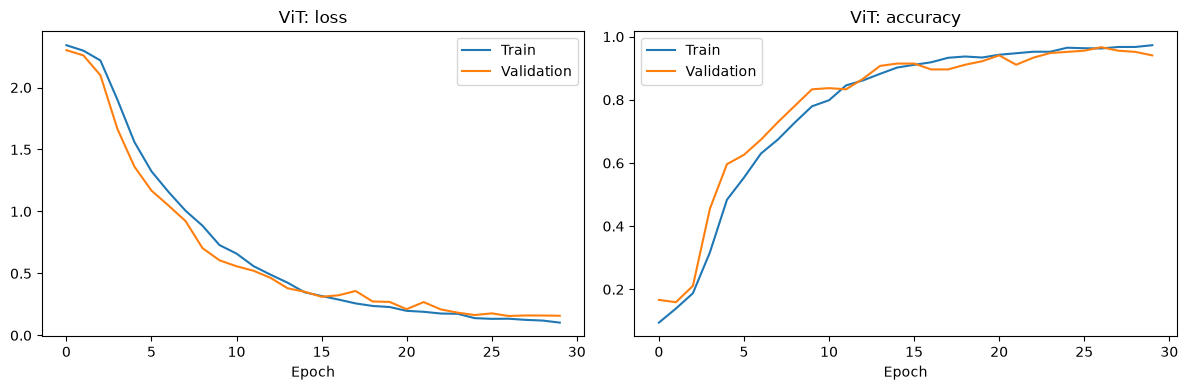

In [31]:
vit_model, vit_history = train_model(
    vit_model,
    train_loader,
    val_loader,
    epochs=EPOCHS,
    learning_rate=5e-4,
)
plot_history(vit_history, "ViT")

## 10. Majority-class baseline

A simple baseline always predicts the most frequent class in the **training split**. We report its performance on the held-out test set. This baseline does not train a neural network.

In [32]:
majority_class = int(np.bincount(y_train).argmax())
baseline_predictions = np.full_like(y_test, fill_value=majority_class)

baseline_accuracy = accuracy_score(y_test, baseline_predictions)
baseline_macro_f1 = f1_score(y_test, baseline_predictions, average="macro", zero_division=0)

print("Majority class from training data:", majority_class)
print(f"Baseline test accuracy: {baseline_accuracy:.4f}")
print(f"Baseline test macro F1: {baseline_macro_f1:.4f}")

Majority class from training data: 3
Baseline test accuracy: 0.1037
Baseline test macro F1: 0.0188


## 11. Final test evaluation

Run this section only after training and model selection are complete. The same held-out test examples are used for both models.

In [33]:
@torch.no_grad()
def get_predictions(model, loader):
    model.eval()
    y_true, y_pred = [], []
    for images, labels in loader:
        logits = model(images.to(DEVICE))
        y_pred.extend(logits.argmax(dim=1).cpu().numpy())
        y_true.extend(labels.numpy())
    return np.array(y_true), np.array(y_pred)

cnn_true, cnn_pred = get_predictions(cnn_model, test_loader)
vit_true, vit_pred = get_predictions(vit_model, test_loader)

results = {
    "Majority baseline": {
        "accuracy": accuracy_score(y_test, baseline_predictions),
        "macro_f1": f1_score(y_test, baseline_predictions, average="macro", zero_division=0),
    },
    "CNN": {
        "accuracy": accuracy_score(cnn_true, cnn_pred),
        "macro_f1": f1_score(cnn_true, cnn_pred, average="macro", zero_division=0),
    },
    "ViT": {
        "accuracy": accuracy_score(vit_true, vit_pred),
        "macro_f1": f1_score(vit_true, vit_pred, average="macro", zero_division=0),
    },
}

for model_name, metrics in results.items():
    print(
        f"{model_name:18s} | "
        f"test accuracy: {metrics['accuracy']:.4f} | "
        f"macro F1: {metrics['macro_f1']:.4f}"
    )

Majority baseline  | test accuracy: 0.1037 | macro F1: 0.0188
CNN                | test accuracy: 0.9926 | macro F1: 0.9925
ViT                | test accuracy: 0.9481 | macro F1: 0.9481


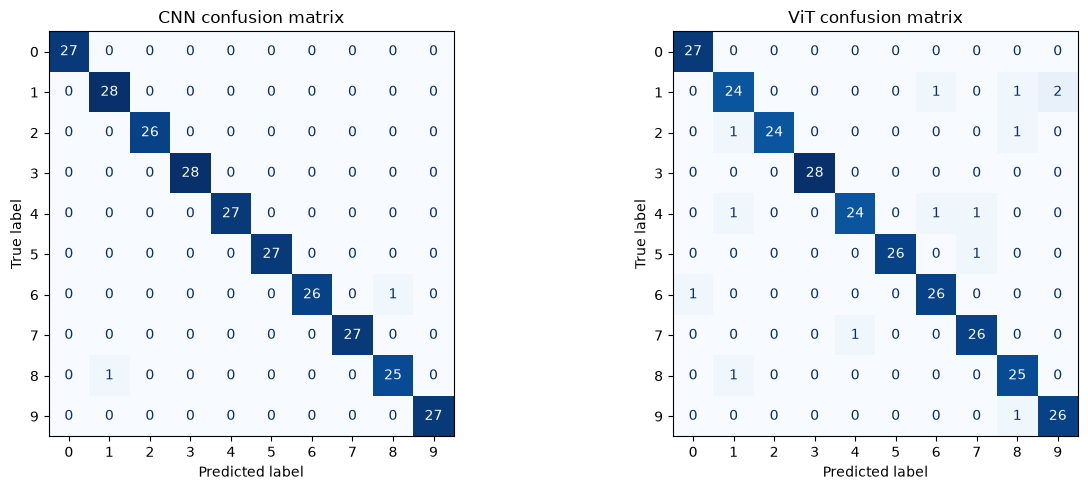

In [39]:
from pathlib import Path

result_dir = Path("result")
result_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, true, pred, name in [
    (axes[0], cnn_true, cnn_pred, "CNN"),
    (axes[1], vit_true, vit_pred, "ViT"),
]:
    cm = confusion_matrix(true, pred, labels=np.arange(10))
    ConfusionMatrixDisplay(cm, display_labels=np.arange(10)).plot(
        ax=ax, cmap="Blues", colorbar=False
    )
    ax.set_title(f"{name} confusion matrix")

plt.tight_layout()
fig.savefig(result_dir / "confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.show()

In [36]:
print("CNN classification report")
print(classification_report(cnn_true, cnn_pred, digits=4, zero_division=0))
print("ViT classification report")
print(classification_report(vit_true, vit_pred, digits=4, zero_division=0))

CNN classification report
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        27
           1     0.9655    1.0000    0.9825        28
           2     1.0000    1.0000    1.0000        26
           3     1.0000    1.0000    1.0000        28
           4     1.0000    1.0000    1.0000        27
           5     1.0000    1.0000    1.0000        27
           6     1.0000    0.9630    0.9811        27
           7     1.0000    1.0000    1.0000        27
           8     0.9615    0.9615    0.9615        26
           9     1.0000    1.0000    1.0000        27

    accuracy                         0.9926       270
   macro avg     0.9927    0.9925    0.9925       270
weighted avg     0.9927    0.9926    0.9926       270

ViT classification report
              precision    recall  f1-score   support

           0     0.9643    1.0000    0.9818        27
           1     0.8889    0.8571    0.8727        28
           2     1.0000   

## 12. Inspect misclassified examples

Review a few errors from each model. Look for visually similar digits and consider whether the 8×8 resolution makes their strokes ambiguous.

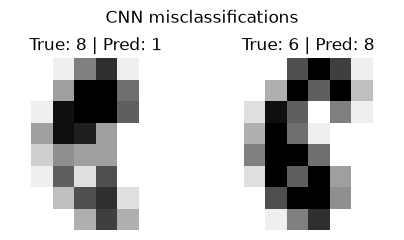

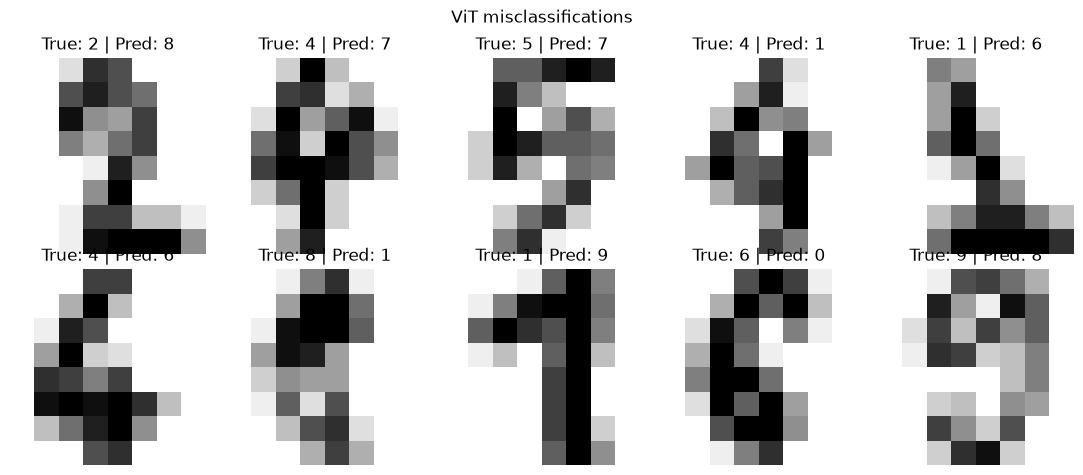

In [37]:
def show_errors(images, true_labels, predictions, title, max_items=10):
    error_indices = np.where(true_labels != predictions)[0][:max_items]
    if len(error_indices) == 0:
        print(f"{title}: no errors on this test split.")
        return

    cols = min(5, len(error_indices))
    rows = int(np.ceil(len(error_indices) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(2.2 * cols, 2.4 * rows))
    axes = np.array(axes).reshape(-1)

    for ax, idx in zip(axes, error_indices):
        ax.imshow(images[idx], cmap="gray_r", vmin=0, vmax=1)
        ax.set_title(f"True: {true_labels[idx]} | Pred: {predictions[idx]}")
        ax.axis("off")
    for ax in axes[len(error_indices):]:
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

show_errors(X_test, cnn_true, cnn_pred, "CNN misclassifications")
show_errors(X_test, vit_true, vit_pred, "ViT misclassifications")

## 13. Reusable uploaded-photo preprocessing (Pillow)

The training data has bright strokes on a dark background and is scaled by dividing by 16. This helper:
- Opens PNG/JPEG data with Pillow.
- Converts to grayscale.
- Inverts images with a bright background.
- Rejects blank images.
- Crops the detected strokes.
- Resizes proportionally and centers them on an 8×8 canvas.
- Scales 8-bit pixels by 255 to the same numerical range [0, 1].

**Note:** This is a practical starting point for a single digit on a reasonably plain background. Complex photos, shadows, colored backgrounds or multiple marks may need stronger segmentation.

In [38]:
def prepare_uploaded_digit(image_or_path, threshold=20):
    # Accept a PIL image, file-like object, or filesystem path.
    image = Image.open(image_or_path) if not isinstance(image_or_path, Image.Image) else image_or_path
    gray = ImageOps.grayscale(image)

    # Normalize polarity: digit strokes should be bright, background dark.
    arr = np.asarray(gray, dtype=np.uint8)
    if arr.mean() > 127:
        gray = ImageOps.invert(gray)

    arr = np.asarray(gray, dtype=np.uint8)
    mask = arr > threshold
    if not mask.any():
        raise ValueError("The uploaded image appears blank. Please upload a clear image containing one digit.")

    ys, xs = np.where(mask)
    left, right = xs.min(), xs.max() + 1
    top, bottom = ys.min(), ys.max() + 1
    cropped = gray.crop((left, top, right, bottom))

    # Keep aspect ratio and leave a one-pixel margin around the digit.
    cropped.thumbnail((6, 6), Image.Resampling.LANCZOS)
    canvas = Image.new("L", (8, 8), color=0)
    paste_x = (8 - cropped.width) // 2
    paste_y = (8 - cropped.height) // 2
    canvas.paste(cropped, (paste_x, paste_y))

    prepared_uint8 = np.asarray(canvas, dtype=np.uint8)
    prepared_float = prepared_uint8.astype(np.float32) / 255.0
    return prepared_float, canvas

# Example using a synthetic image is optional; pass a path or uploaded file to the function.
# prepared_array, prepared_pil = prepare_uploaded_digit("my_digit.png")
# plt.figure(figsize=(3, 3))
# plt.imshow(prepared_pil.resize((240, 240), Image.Resampling.NEAREST), cmap="gray")
# plt.title("Prepared 8x8 digit")
# plt.axis("off")
# plt.show()

## 14. Predict one prepared image with both models

This helper returns each model's predicted digit and softmax probabilities. It expects the same `[0, 1]` 8×8 representation produced by `prepare_uploaded_digit`.

In [ ]:
@torch.no_grad()
def predict_both(prepared_8x8):
    image_tensor = torch.tensor(
        prepared_8x8, dtype=torch.float32
    ).unsqueeze(0).unsqueeze(0).to(DEVICE)  # [1, 1, 8, 8]

    cnn_model.eval()
    vit_model.eval()

    cnn_probs = torch.softmax(cnn_model(image_tensor), dim=1).squeeze(0).cpu().numpy()
    vit_probs = torch.softmax(vit_model(image_tensor), dim=1).squeeze(0).cpu().numpy()

    return {
        "cnn_digit": int(cnn_probs.argmax()),
        "cnn_probabilities": cnn_probs,
        "vit_digit": int(vit_probs.argmax()),
        "vit_probabilities": vit_probs,
    }

# Example:
# prepared_array, prepared_preview = prepare_uploaded_digit("my_digit.png")
# output = predict_both(prepared_array)
# print("CNN:", output["cnn_digit"])
# print("ViT:", output["vit_digit"])

## 15. Save model checkpoints and project settings

The Streamlit app should load these files at startup and must not retrain models. Checkpoints include architecture settings and the expected preprocessing scale.

In [40]:
ARTIFACT_DIR = Path("artifacts")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

cnn_checkpoint = {
    "model_name": "SmallCNN",
    "model_state_dict": cnn_model.cpu().state_dict(),
    "num_classes": 10,
    "input_shape": [1, 8, 8],
    "pixel_scale": "divide_by_16_for_sklearn; divide_by_255_for_uploaded_8bit",
    "class_mapping": {i: str(i) for i in range(10)},
}
vit_checkpoint = {
    "model_name": "SmallViT",
    "model_state_dict": vit_model.cpu().state_dict(),
    "config": {
        "image_size": 8,
        "patch_size": 2,
        "embed_dim": 64,
        "num_heads": 4,
        "num_layers": 2,
        "mlp_dim": 128,
        "num_classes": 10,
        "dropout": 0.10,
    },
    "pixel_scale": "divide_by_16_for_sklearn; divide_by_255_for_uploaded_8bit",
    "class_mapping": {i: str(i) for i in range(10)},
}

torch.save(cnn_checkpoint, ARTIFACT_DIR / "cnn_model.pth")
torch.save(vit_checkpoint, ARTIFACT_DIR / "vit_model.pth")

print("Saved:")
print(ARTIFACT_DIR / "cnn_model.pth")
print(ARTIFACT_DIR / "vit_model.pth")

# Move models back to the selected device for continued notebook use.
cnn_model.to(DEVICE)
vit_model.to(DEVICE)

Saved:
artifacts\cnn_model.pth
artifacts\vit_model.pth


SmallViT(
  (patch_projection): Linear(in_features=4, out_features=64, bias=True)
  (transformer): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (linear1): Linear(in_features=64, out_features=128, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=128, out_features=64, bias=True)
        (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
  (head): Linear(in_features=64, out_features=10, bias=True)
)

## 16. Verify that checkpoints reload correctly

This is a quick reproducibility check. The loaded models should produce the same predictions as the in-memory models.

In [ ]:
# weights_only=False is used because this checkpoint contains ordinary Python metadata
# as well as the state dictionary. Only load checkpoints you created/trust.
cnn_loaded_ckpt = torch.load(ARTIFACT_DIR / "cnn_model.pth", map_location=DEVICE, weights_only=False)
vit_loaded_ckpt = torch.load(ARTIFACT_DIR / "vit_model.pth", map_location=DEVICE, weights_only=False)

cnn_reloaded = SmallCNN().to(DEVICE)
cnn_reloaded.load_state_dict(cnn_loaded_ckpt["model_state_dict"])
cnn_reloaded.eval()

vit_reloaded = SmallViT(**vit_loaded_ckpt["config"]).to(DEVICE)
vit_reloaded.load_state_dict(vit_loaded_ckpt["model_state_dict"])
vit_reloaded.eval()

with torch.no_grad():
    check_x = torch.tensor(X_test[:8], dtype=torch.float32).unsqueeze(1).to(DEVICE)
    original_cnn = cnn_model(check_x).argmax(1)
    reloaded_cnn = cnn_reloaded(check_x).argmax(1)
    original_vit = vit_model(check_x).argmax(1)
    reloaded_vit = vit_reloaded(check_x).argmax(1)

print("CNN reload matches:", torch.equal(original_cnn, reloaded_cnn))
print("ViT reload matches:", torch.equal(original_vit, reloaded_vit))

SyntaxError: invalid syntax. Perhaps you forgot a comma? (1481262980.py, line 3)

## 17. Summary and hand-off to Streamlit

Before moving to the app, confirm:
- [ ] Dataset is from `sklearn.datasets.load_digits()`.
- [ ] Training pixels are divided by 16.
- [ ] Both models use the exact same stratified split.
- [ ] CNN input is `[N, 1, 8, 8]` and output is `[N, 10]`.
- [ ] ViT creates `[N, 16, 4]` patches, projects them, adds positions and uses Transformer attention.
- [ ] Both models are evaluated on the same held-out test set.
- [ ] Accuracy, macro F1, confusion matrices and majority baseline are reported.
- [ ] Both checkpoints reload successfully.
- [ ] Upload preprocessing returns an 8×8 array in [0, 1].

### Run the eventual Streamlit app

After creating `app.py` and placing the saved checkpoints where the app expects them:

```bash
pip install torch scikit-learn streamlit pillow numpy matplotlib
streamlit run app.py
```

**Interpretation prompt:** Which model performed better on the held-out test set? Did that model also make fewer mistakes on visually similar digits? Why might a real-world phone photo perform worse than a sample from sklearn's digits dataset?